# 🔍 04 - Seaborn: Relationships and Categories

Notebook 03 drew the shape of **one** variable at a time. This notebook draws how variables relate: two numeric columns (scatter plots and trend lines), a numeric column across categories (bar and point plots), and whole tables at once (heatmaps and pair plots).

Two promises from Module 07 get paid off here: the penguin **Simpson's paradox** from the lab, and the Anscombe datasets with a straight line fitted through them.

## ✅ Learning Goals
- Draw scatter plots with `hue`, `style`, and `size`, and handle overplotting with transparency
- Add trend lines with `sns.regplot()` / `sns.lmplot()`, and see why one line can mislead
- Show Simpson's paradox in a single chart
- Choose between `countplot`, `barplot`, and `pointplot`, and explain what Seaborn's error bars mean
- Turn a correlation matrix and a pivot table into heatmaps, with the right color scale for each
- Survey every pair of variables with `sns.pairplot()`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from pathlib import Path

OUT = Path('04-OutputFiles')
OUT.mkdir(exist_ok=True)

sns.set_theme(style='whitegrid')

MEASUREMENTS = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
SPECIES_ORDER = ['Adelie', 'Chinstrap', 'Gentoo']

penguins = pd.read_csv('penguins.csv').dropna(subset=MEASUREMENTS)
penguins['sex'] = penguins['sex'].str.title()

titanic = pd.read_csv('titanic.csv')
titanic['class'] = titanic['Pclass'].map({1: '1st', 2: '2nd', 3: '3rd'})

## 1. Scatter Plots with `sns.scatterplot()`
Each point is one row. Extra columns can control the point's **color** (`hue`), **marker shape** (`style`), and **size** (`size`):

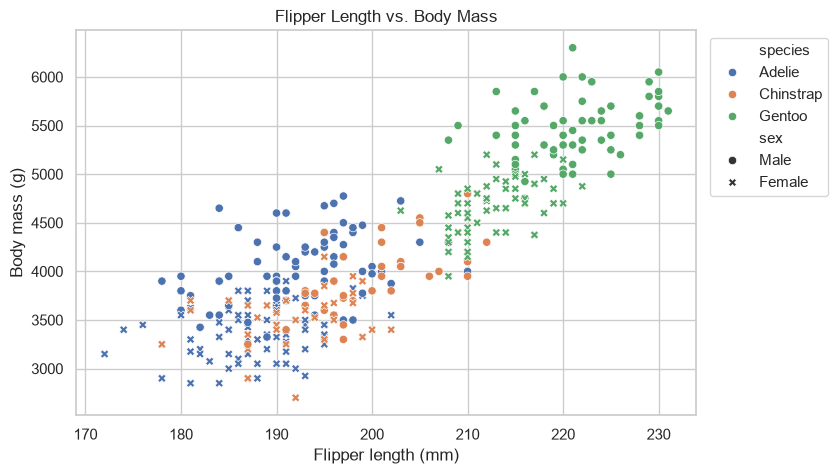

In [2]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=penguins, x='flipper_length_mm', y='body_mass_g',
                hue='species', style='sex', hue_order=SPECIES_ORDER, ax=ax)
ax.set(title='Flipper Length vs. Body Mass', xlabel='Flipper length (mm)', ylabel='Body mass (g)')
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.show()

This is Module 07's strongest correlation (r ≈ 0.87), and now you can see its structure: three clusters (species), with males heavier within each one.

⚠️ Each extra encoding is one more thing for the reader to decode. `hue` + `style` is about the limit. Beyond that, use panels (`sns.relplot(..., col=)`, the figure-level version of `scatterplot`).

### Overplotting
When many points land in the same place, they hide each other. Titanic `Age` vs. `Fare` has 714 points piled up at low fares:

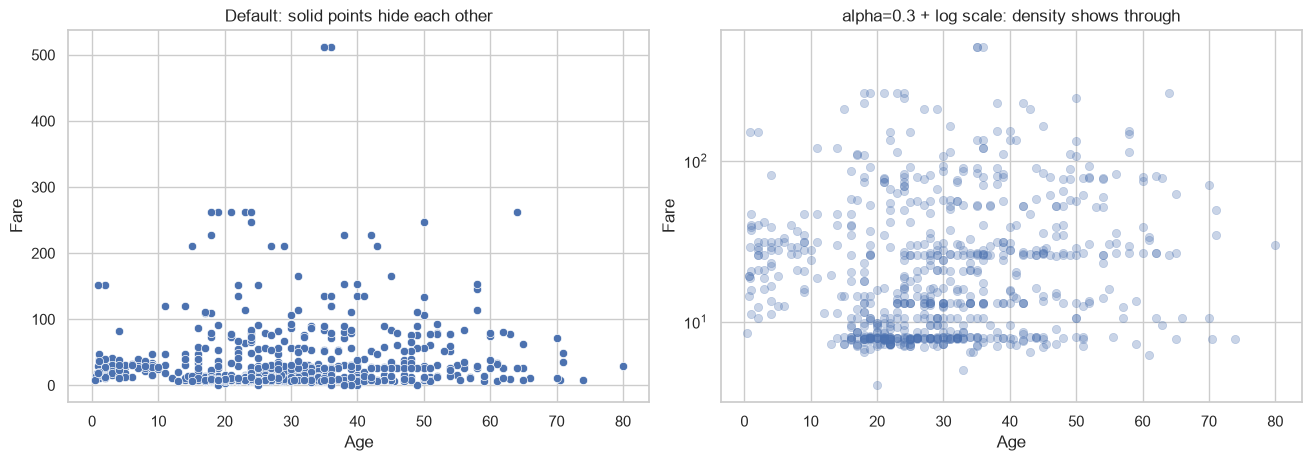

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout='constrained')

sns.scatterplot(data=titanic, x='Age', y='Fare', ax=axes[0])
axes[0].set(title='Default: solid points hide each other')

sns.scatterplot(data=titanic, x='Age', y='Fare', alpha=0.3, edgecolor=None, ax=axes[1])
axes[1].set(yscale='log', title='alpha=0.3 + log scale: density shows through')
plt.show()

Transparency (`alpha`) makes dense areas darker, and the log scale (notebook 01) spreads out the crowded low fares.

## 2. Trend Lines with `sns.regplot()`
`regplot` draws a scatter plot plus a fitted straight line, with a shaded band showing how uncertain the line is:

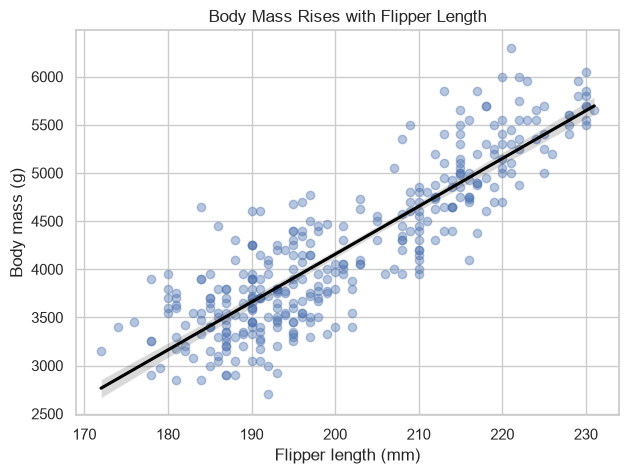

In [4]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.regplot(data=penguins, x='flipper_length_mm', y='body_mass_g',
            scatter_kws={'alpha': 0.4}, line_kws={'color': 'black'}, ax=ax)
ax.set(title='Body Mass Rises with Flipper Length', xlabel='Flipper length (mm)', ylabel='Body mass (g)')
plt.show()

## 3. 🤯 The Penguin Paradox, Made Visible
The Module 07 lab found that bill length and bill depth correlate **negatively** overall (r ≈ −0.24), but **positively within every species** (r ≈ +0.39 to +0.65). It took a table and a loop to find. Here it is in one figure:

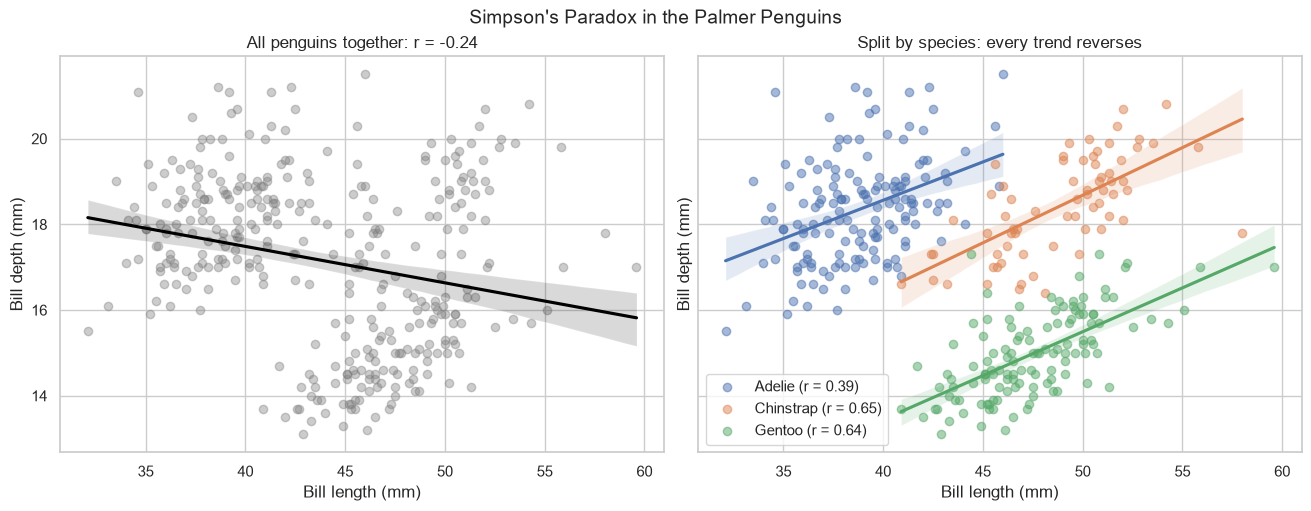

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True, layout='constrained')

# Left: everyone together, one line
sns.regplot(data=penguins, x='bill_length_mm', y='bill_depth_mm', ax=axes[0],
            scatter_kws={'alpha': 0.4, 'color': 'gray'}, line_kws={'color': 'black'})
r_all = penguins['bill_length_mm'].corr(penguins['bill_depth_mm'])
axes[0].set(title=f'All penguins together: r = {r_all:.2f}')

# Right: one line per species
palette = dict(zip(SPECIES_ORDER, sns.color_palette(n_colors=3)))
for species, group in penguins.groupby('species'):
    r = group['bill_length_mm'].corr(group['bill_depth_mm'])
    sns.regplot(data=group, x='bill_length_mm', y='bill_depth_mm', ax=axes[1],
                color=palette[species], scatter_kws={'alpha': 0.5}, label=f'{species} (r = {r:.2f})')
axes[1].set(title='Split by species: every trend reverses')
axes[1].legend()

for ax in axes:
    ax.set(xlabel='Bill length (mm)', ylabel='Bill depth (mm)')

fig.suptitle("Simpson's Paradox in the Palmer Penguins", fontsize=14)
fig.savefig(OUT / 'penguin_paradox.png', dpi=150, bbox_inches='tight')
plt.show()

On the right, you can see **why**: the Gentoo cluster sits in the lower right (long, shallow bills), and the other two sit higher up. A single line through all three clusters slopes down, even though each cluster slopes up.

The left chart isn't "wrong" (it's the correct line for all the data combined), but it answers a question nobody meant to ask. **Whenever your data contain groups, color by group before you fit a line.**

## 4. Anscombe, One More Time
Notebook 01 showed the four Anscombe datasets. `sns.lmplot()` is the figure-level `regplot`: it fits a line in every panel:

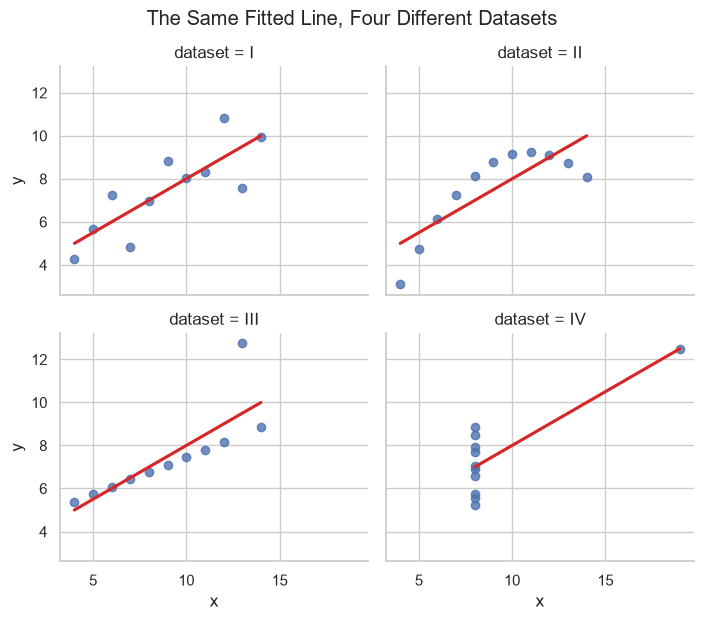

In [6]:
anscombe = pd.read_csv('anscombe.csv')

g = sns.lmplot(data=anscombe, x='x', y='y', col='dataset', col_wrap=2,
               height=3, aspect=1.2, ci=None, line_kws={'color': 'tab:red'})
g.figure.suptitle('The Same Fitted Line, Four Different Datasets', y=1.03)
plt.show()

The four red lines are **identical**: same slope, same intercept. A fitted line is another summary statistic, and it can hide just as much as a mean. Only dataset I is described well by its line. Look at the points before you trust the line.

✅ **Your Turn:** `regplot` can fit a curve with `order=2`. Redraw dataset II alone with `order=2`. Does the curve fit better than the straight line?

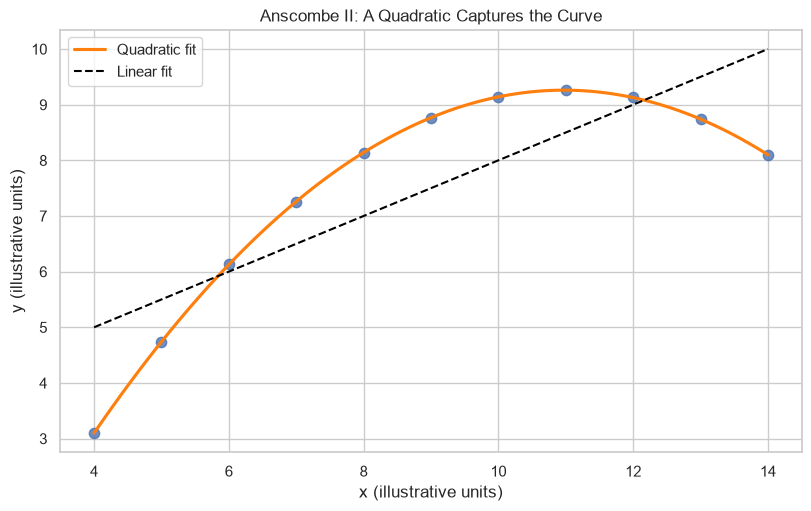

In-sample MSE: linear 1.25239008; quadratic 0.00000203.
Yes: the quadratic closely follows the curved points, while the straight line misses the systematic bend.
This describes these 11 observations; it does not establish a causal law or justify extrapolation.


In [7]:
dataset_ii = anscombe.loc[anscombe['dataset'] == 'II']
fig, ax = plt.subplots(figsize=(8, 5), layout='constrained')
sns.regplot(data=dataset_ii, x='x', y='y', order=2, ci=None,
            scatter_kws={'s': 55}, line_kws={'color': 'tab:orange', 'label': 'Quadratic fit'}, ax=ax)
linear_coefficients = np.polyfit(dataset_ii['x'], dataset_ii['y'], deg=1)
quadratic_coefficients = np.polyfit(dataset_ii['x'], dataset_ii['y'], deg=2)
x_grid = np.linspace(dataset_ii['x'].min(), dataset_ii['x'].max(), 200)
ax.plot(x_grid, np.polyval(linear_coefficients, x_grid), color='black', linestyle='--', label='Linear fit')
ax.set(title='Anscombe II: A Quadratic Captures the Curve', xlabel='x (illustrative units)', ylabel='y (illustrative units)')
ax.legend()
fig.savefig(OUT / 'anscombe_ii_quadratic.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)
linear_mse = np.mean((dataset_ii['y'] - np.polyval(linear_coefficients, dataset_ii['x'])) ** 2)
quadratic_mse = np.mean((dataset_ii['y'] - np.polyval(quadratic_coefficients, dataset_ii['x'])) ** 2)
print(f'In-sample MSE: linear {linear_mse:.8f}; quadratic {quadratic_mse:.8f}.')
print('Yes: the quadratic closely follows the curved points, while the straight line misses the systematic bend.')
print('This describes these 11 observations; it does not establish a causal law or justify extrapolation.')


## 5. Categories: Counts, Estimates, and Error Bars
### `countplot`: how many rows in each category

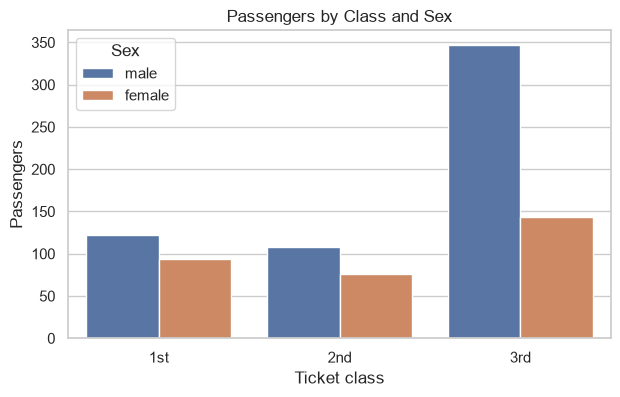

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=titanic, x='class', hue='Sex', order=['1st', '2nd', '3rd'], ax=ax)
ax.set(title='Passengers by Class and Sex', xlabel='Ticket class', ylabel='Passengers')
plt.show()

### `barplot`: an **estimate** for each category
`sns.barplot()` computes a statistic of `y` for each group (the **mean**, by default) and draws an **error bar** on top. Since `Survived` is 0/1, the mean is the survival **rate** (Module 07 notebook 01):

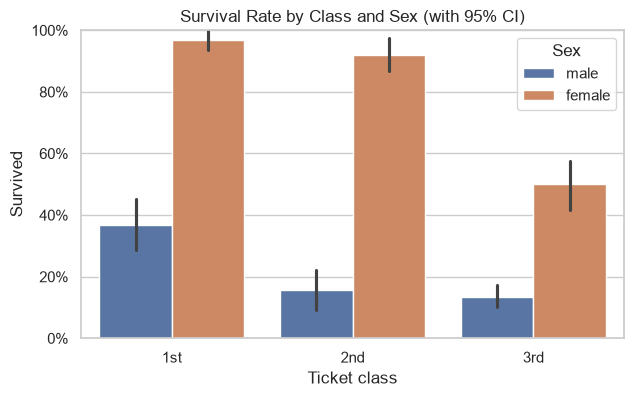

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=titanic, x='class', y='Survived', hue='Sex', order=['1st', '2nd', '3rd'], ax=ax)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.set(title='Survival Rate by Class and Sex (with 95% CI)', xlabel='Ticket class', ylabel='Survived', ylim=(0, 1))
plt.show()

Compare this with notebook 02's pandas version. You get the same bars, but Seaborn computed the rates from the raw rows (no `pivot_table` needed) and added error bars.

**What do the error bars mean?** By default, a 95% **confidence interval**: a range showing how much the estimate might change with a different sample of passengers. Narrow bars mean a precise estimate, usually from a big group. Seaborn's `errorbar=` changes what's drawn:

| `errorbar=` | Shows | Answers |
|---|---|---|
| `('ci', 95)` (default) | 95% confidence interval of the mean | "How sure am I about this group's average?" |
| `'se'` | ± one standard error | the same question, with a narrower band |
| `'sd'` | ± one standard deviation | "How spread out are the individual values?" (Module 07 notebook 02) |
| `None` | nothing | |

> ⚠️ Always say which one you drew. A reader can't tell an SD bar from a CI bar by looking. The CI uses random resampling, so its exact ends can shift slightly between runs. Pass `seed=` for repeatable results.

### `pointplot`: the same estimates, connected
A **point plot** draws each estimate as a dot. With `hue`, it connects the dots for each hue level, which makes differences in the **pattern** easy to compare:

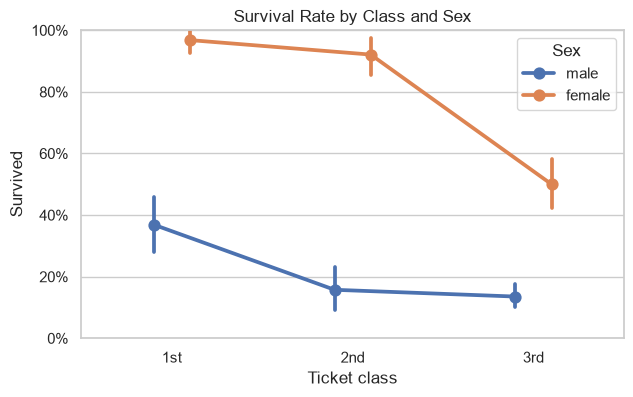

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.pointplot(data=titanic, x='class', y='Survived', hue='Sex', order=['1st', '2nd', '3rd'],
              dodge=0.2, ax=ax)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.set(title='Survival Rate by Class and Sex', xlabel='Ticket class', ylabel='Survived', ylim=(0, 1))
plt.show()

The two lines aren't parallel. For women, the big drop is from 2nd to 3rd class. For men, it's from 1st to 2nd. When lines like these cross or diverge, the effect of one variable **depends on** the other (an **interaction**). Lines suit an ordered x-axis like class (Foundations 07). For an unordered one, prefer bars.

## 6. Heatmaps
A heatmap colors each cell of a table. Two tables from Module 07 are perfect for it.

### A correlation matrix
Correlations run from −1 to +1, with 0 meaning "nothing." That calls for a **diverging** color map, centered on 0. And because the matrix is symmetric (Module 07 notebook 05), mask the redundant upper triangle:

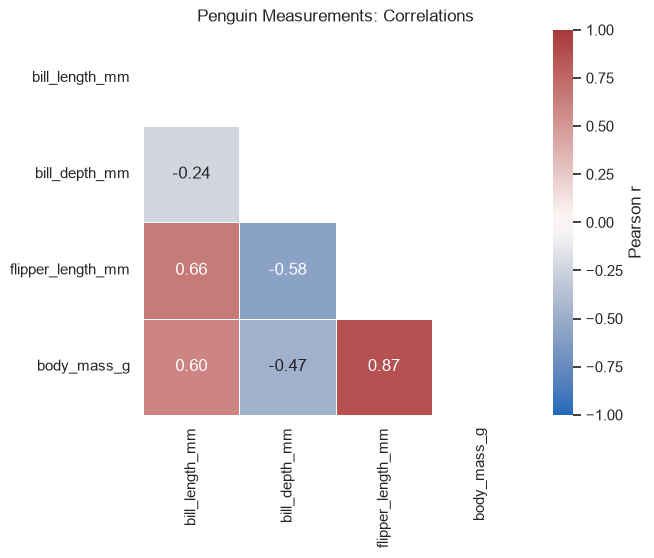

In [11]:
corr = penguins[MEASUREMENTS].corr()
mask = np.triu(np.ones(corr.shape, dtype=bool))          # hide the diagonal and above

fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, center=0,
            square=True, linewidths=0.5, cbar_kws={'label': 'Pearson r'}, ax=ax)
ax.set(title='Penguin Measurements: Correlations')
ax.grid(False)          # the whitegrid theme would draw lines through the masked cells
plt.show()

- `cmap='vlag'`: blue for negative, red for positive, and pale near zero.
- `vmin=-1, vmax=1, center=0`: fixes the color scale, so the same color always means the same r, in every heatmap you make.
- `annot=True, fmt='.2f'`: prints the numbers too. Color for the pattern, numbers for the detail.

### A pivot table of rates
Survival rates run from 0 to 1, with no meaningful middle. That calls for a **sequential** color map (light to dark):

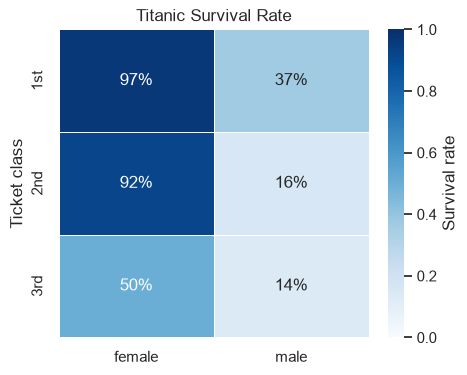

In [12]:
rates = titanic.pivot_table(values='Survived', index='class', columns='Sex', aggfunc='mean')

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(rates, annot=True, fmt='.0%', cmap='Blues', vmin=0, vmax=1,
            linewidths=0.5, cbar_kws={'label': 'Survival rate'}, ax=ax)
ax.set(title='Titanic Survival Rate', xlabel='', ylabel='Ticket class')
ax.grid(False)
plt.show()

| Data | Color map type | Examples |
|---|---|---|
| has a meaningful middle (correlation, change, difference) | **diverging** | `'vlag'`, `'coolwarm'`, `'RdBu'` |
| low to high, no middle (counts, rates, amounts) | **sequential** | `'Blues'`, `'viridis'`, `'rocket'` |
| unordered categories | **qualitative** | `'tab10'`, `'Set2'`, `'colorblind'` |

## 7. Every Pair at Once: `sns.pairplot()`
`pairplot` draws a scatter plot for every pair of numeric columns, with each column's distribution on the diagonal. It's the visual version of the full correlation matrix. `corner=True` skips the redundant upper half:

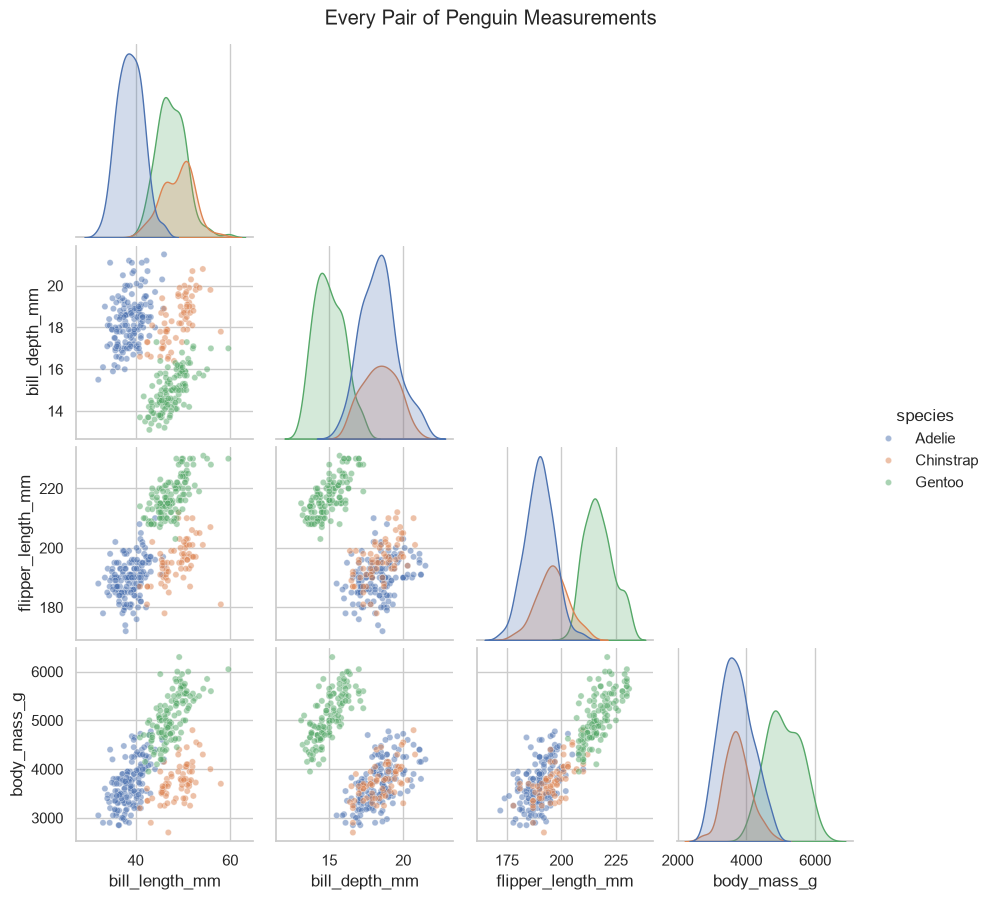

In [13]:
g = sns.pairplot(penguins, vars=MEASUREMENTS, hue='species', hue_order=SPECIES_ORDER,
                 corner=True, height=2.2, plot_kws={'alpha': 0.5, 's': 20})
g.figure.suptitle('Every Pair of Penguin Measurements', y=1.02)
g.savefig(OUT / 'penguin_pairplot.png', dpi=120, bbox_inches='tight')
plt.show()

A pairplot is an **exploration** tool: fast, broad, and too busy to show anyone else. Use it to decide which two or three charts deserve to be made properly. (Which pair separates the three species most cleanly?)

**Reading the pairplot:** Bill length against bill depth separates the species particularly clearly: Gentoo bills tend to be shallower, Adelie bills shorter, and Chinstrap bills longer and deeper. Some overlap remains, so the picture is not a perfect species classifier.


---
### 📝 Summary
- `scatterplot` with `hue`/`style`/`size`. Fix overplotting with `alpha` and log scales.
- `regplot`/`lmplot` add fitted lines, and a line is a summary that can mislead (Anscombe).
- **Color by group before you fit a line**: one chart reveals Simpson's paradox.
- `countplot` counts rows, `barplot` estimates a statistic with an error bar, and `pointplot` connects estimates to show interactions. Say what your error bars mean.
- Heatmaps: diverging color maps (centered) for correlations, sequential ones for amounts. Fix `vmin`/`vmax`.
- `pairplot` for exploration, not presentation.

## 🏋️ Practice

### Practice 1 — Pokémon Scatter (easy)
Load `pokemon.csv`. Make a scatter plot of `Attack` vs. `Sp. Atk`, colored by `Legendary`, with transparency. Where do the Legendary Pokémon sit?

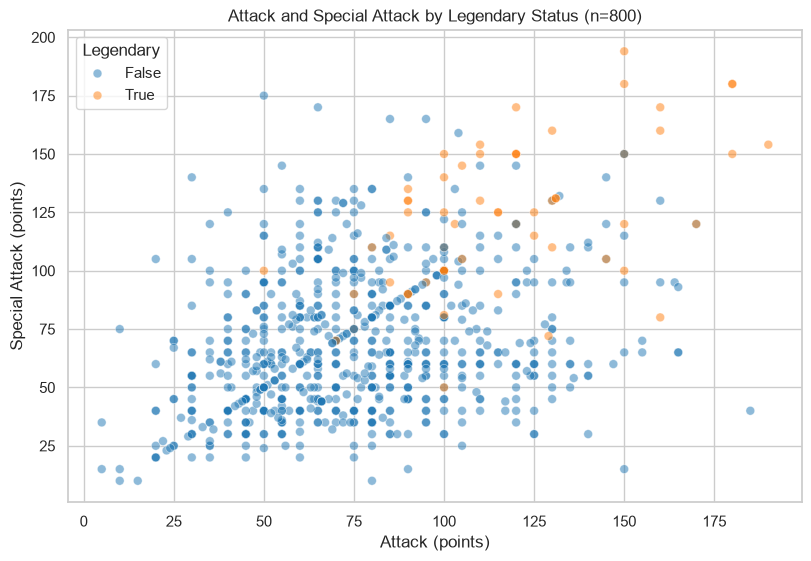

,n,median_attack,median_special_attack
Legendary,,,
False,735,72.0,65.0
True,65,110.0,120.0


Legendary records generally sit toward the upper right, with substantial overlap with non-Legendary records.
Their median Attack/Special Attack are 110/120 versus 72/65 for non-Legendary records (n=65 versus 735).


In [14]:
poke = pd.read_csv('pokemon.csv')
pokemon_scatter = poke.dropna(subset=['Attack', 'Sp. Atk', 'Legendary'])
fig, ax = plt.subplots(figsize=(8, 5.5), layout='constrained')
sns.scatterplot(data=pokemon_scatter, x='Attack', y='Sp. Atk', hue='Legendary',
                hue_order=[False, True], palette={False: 'tab:blue', True: 'tab:orange'},
                alpha=0.5, s=40, ax=ax)
ax.set(title=f'Attack and Special Attack by Legendary Status (n={len(pokemon_scatter)})',
       xlabel='Attack (points)', ylabel='Special Attack (points)')
ax.legend(title='Legendary')
fig.savefig(OUT / 'pokemon_attack_special_attack.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)
legendary_summary = pokemon_scatter.groupby('Legendary').agg(
    n=('Attack', 'size'), median_attack=('Attack', 'median'), median_special_attack=('Sp. Atk', 'median'))
display(legendary_summary)
print('Legendary records generally sit toward the upper right, with substantial overlap with non-Legendary records.')
print('Their median Attack/Special Attack are 110/120 versus 72/65 for non-Legendary records (n=65 versus 735).')


### Practice 2 — A Heatmap of Pokémon Stats (medium)
Draw a masked, annotated correlation heatmap of the six Pokémon stats with a diverging color map fixed at −1 to 1. Which pair is strongest? Does that match your Module 07 notebook 05 results?

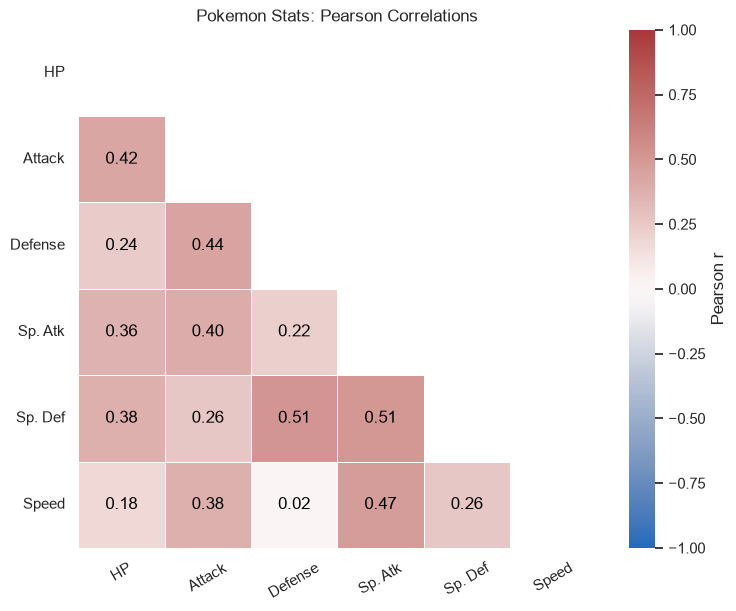

Defense  Sp. Def    0.510747
Sp. Atk  Sp. Def    0.506121
         Speed      0.473018
Attack   Defense    0.438687
HP       Attack     0.422386
Name: pearson_r, dtype: float64

Strongest unique pair: Defense and Sp. Def, r=0.510747; this matches Module 07 notebook 05.
Self-correlations and mirrored duplicates are excluded; all six numeric stats have 800 known values.


In [15]:
stats = ['HP', 'Attack', 'Defense', 'Sp. Atk', 'Sp. Def', 'Speed']
pokemon_corr = poke[stats].corr()
pokemon_mask = np.triu(np.ones(pokemon_corr.shape, dtype=bool))
fig, ax = plt.subplots(figsize=(8, 6), layout='constrained')
sns.heatmap(pokemon_corr, mask=pokemon_mask, annot=True, annot_kws={'color': 'black'}, fmt='.2f', cmap='vlag',
            vmin=-1, vmax=1, center=0, square=True, linewidths=0.5,
            cbar_kws={'label': 'Pearson r'}, ax=ax)
ax.set(title='Pokemon Stats: Pearson Correlations')
ax.tick_params(axis='x', rotation=30)
ax.tick_params(axis='y', rotation=0)
ax.grid(False)
fig.savefig(OUT / 'pokemon_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)
pokemon_pairs = (pokemon_corr.where(np.triu(np.ones(pokemon_corr.shape, dtype=bool), k=1))
                 .stack().dropna().sort_values(key=abs, ascending=False))
display(pokemon_pairs.head(5).rename('pearson_r'))
print('Strongest unique pair: Defense and Sp. Def, r=0.510747; this matches Module 07 notebook 05.')
print('Self-correlations and mirrored duplicates are excluded; all six numeric stats have 800 known values.')


### Practice 3 — Bars With Honest Error Bars (harder)
Draw mean `body_mass_g` by `species` twice, side by side: once with `errorbar=('ci', 95)` and once with `errorbar='sd'`. Use the same y-axis. In a Markdown cell, explain why the SD bars are so much longer, and which one you'd use to answer (a) "how precisely do we know the Gentoo average?" and (b) "how much do individual Gentoos vary?"

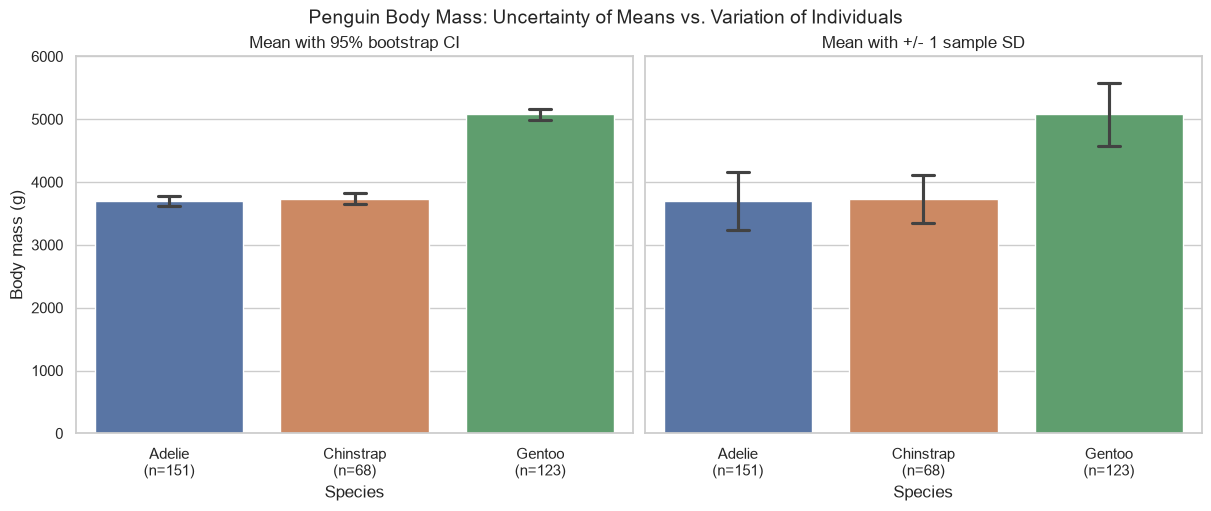

,count,mean,std
species,,,
Adelie,151,3700.66,458.57
Chinstrap,68,3733.09,384.34
Gentoo,123,5076.02,504.12


In [16]:
mass_summary = penguins.groupby('species')['body_mass_g'].agg(['count', 'mean', 'std']).reindex(SPECIES_ORDER)
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True, layout='constrained')
for ax, errorbar, title in zip(axes, [('ci', 95), 'sd'],
                              ['Mean with 95% bootstrap CI', 'Mean with +/- 1 sample SD']):
    sns.barplot(data=penguins, x='species', y='body_mass_g', hue='species',
                order=SPECIES_ORDER, hue_order=SPECIES_ORDER, palette=palette,
                legend=False, errorbar=errorbar, seed=2026, n_boot=2000, capsize=0.12, ax=ax)
    ax.set(title=title, xlabel='Species', ylabel='Body mass (g)', ylim=(0, 6000))
    ax.set_xticks(range(3), [f'{species}\n(n={int(mass_summary.loc[species, "count"])})' for species in SPECIES_ORDER])
fig.suptitle('Penguin Body Mass: Uncertainty of Means vs. Variation of Individuals', fontsize=14)
fig.savefig(OUT / 'body_mass_ci_vs_sd.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)
display(mass_summary.round(2))


The left panel shows **95% bootstrap confidence intervals of species means** (2,000 resamples, seed 2026); the right shows **mean plus/minus one sample standard deviation**, using the same axes and species order. SD describes the spread of individual masses, while a mean is estimated from many observations and has much smaller uncertainty (roughly proportional to SD divided by the square root of n), so the SD bars are substantially longer.

For (a), how precisely the Gentoo average is estimated, use the **95% CI**. For (b), how much individual Gentoos vary, use **SD**, which is **504.12 g**, around a mean of **5,076.02 g**, with **123** complete-measurement Gentoo records. The SD interval is not a confidence interval or automatically a range containing 95% of individuals; bootstrap CIs also do not remove sampling bias or make this an experiment.


## ✏️ Your Turn
Use `sns.lmplot()` with `hue='species'` and `col='sex'` to show the relationship between `flipper_length_mm` and `body_mass_g`. Save it as `OUT / 'flipper_mass_lmplot.png'`. Does the relationship look the same for every species and both sexes?

Faceted chart uses 333 of 342 complete-measurement rows; 9 missing sex values are excluded.


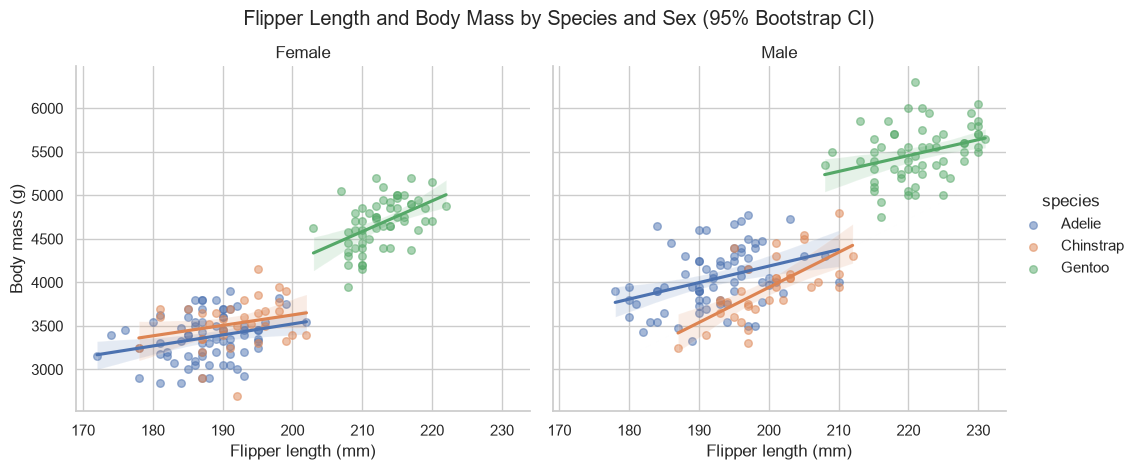

,species,sex,n,pearson_r,slope_g_per_mm
0,Adelie,Female,73,0.2629,12.6591
1,Adelie,Male,73,0.3604,18.9418
2,Chinstrap,Female,34,0.2422,12.0077
3,Chinstrap,Male,34,0.6646,40.2694
4,Gentoo,Female,58,0.4876,35.2252
5,Gentoo,Male,61,0.3305,18.2407


In [17]:
sex_order = ['Female', 'Male']
sex_complete = penguins.dropna(subset=['species', 'sex', 'flipper_length_mm', 'body_mass_g']).copy()
print(f'Faceted chart uses {len(sex_complete)} of {len(penguins)} complete-measurement rows; {penguins["sex"].isna().sum()} missing sex values are excluded.')
g = sns.lmplot(data=sex_complete, x='flipper_length_mm', y='body_mass_g',
               hue='species', hue_order=SPECIES_ORDER, palette=palette,
               col='sex', col_order=sex_order, height=4.5, aspect=1.15,
               scatter_kws={'alpha': 0.5, 's': 30}, ci=95, n_boot=2000, seed=2026)
g.set_axis_labels('Flipper length (mm)', 'Body mass (g)')
g.set_titles('{col_name}')
g.figure.suptitle('Flipper Length and Body Mass by Species and Sex (95% Bootstrap CI)', y=1.04)
g.savefig(OUT / 'flipper_mass_lmplot.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(g.figure)
regression_rows = []
for (species, sex), group in sex_complete.groupby(['species', 'sex']):
    regression_rows.append({'species': species, 'sex': sex, 'n': len(group),
                            'pearson_r': group['flipper_length_mm'].corr(group['body_mass_g']),
                            'slope_g_per_mm': np.polyfit(group['flipper_length_mm'], group['body_mass_g'], 1)[0]})
regression_summary = pd.DataFrame(regression_rows)
display(regression_summary.round(4))


All six species/sex groups have **positive fitted slopes**, but the relationships differ in baseline mass, strength, and estimated slope. The within-group correlations range from **0.2422** (Chinstrap females, n=34) to **0.6646** (Chinstrap males, n=34); slopes range from **12.01 to 40.27 g/mm**. Thus the common upward direction is consistent, while a single line would hide meaningful group structure; the plotted bootstrap bands show uncertainty, and slope differences alone are not a formal significance test.

The chart includes **333 records** after excluding 9 missing sex labels from the 342 complete-measurement records. Group sizes are Adelie Female/Male **73/73**, Chinstrap **34/34**, and Gentoo **58/61**. These are observational associations and do not show that increasing a flipper's length causes increased body mass.


## 🔥 Challenge (Optional) — Hunt for Another Paradox
The Module 07 lab's Practice 3 asked whether bill length/depth was the only pair that reverses within species. Answer it visually: use `sns.lmplot(..., hue='species')` on every pair of measurements (a loop over the pairs), plus a single `regplot` for the combined data. Which pairs, if any, have a combined slope with the opposite sign from all three species' slopes?

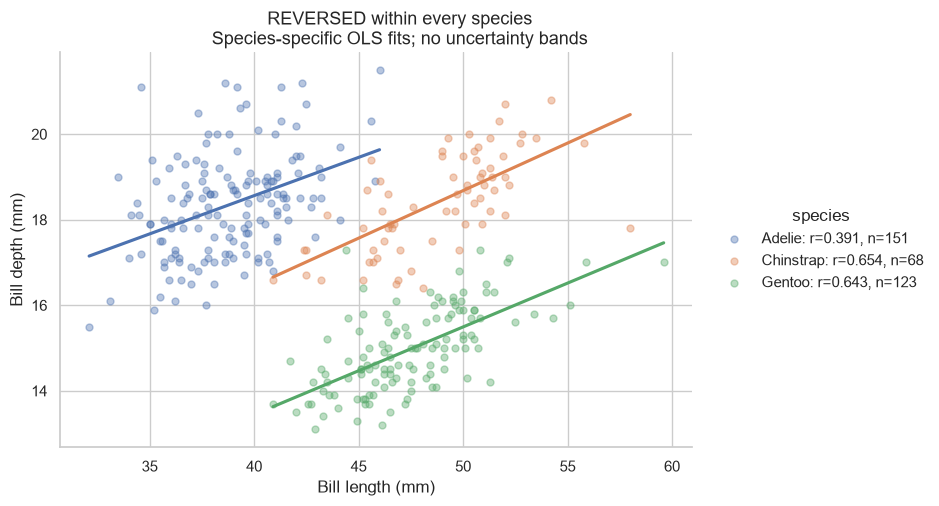

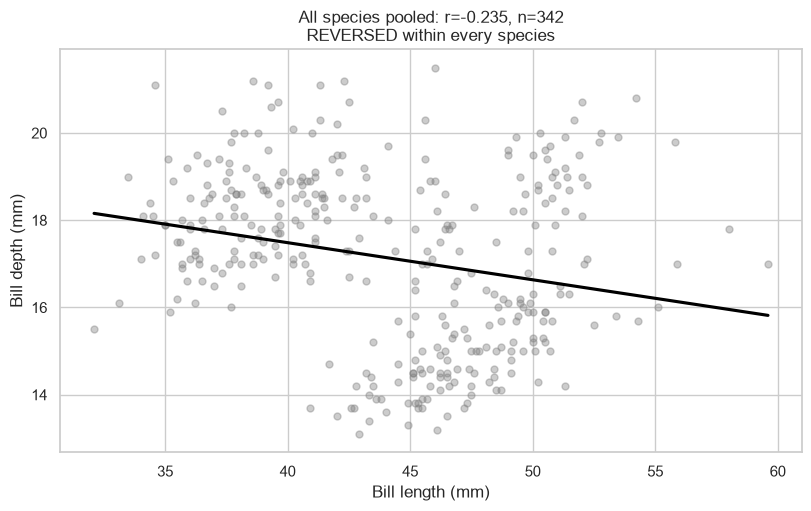

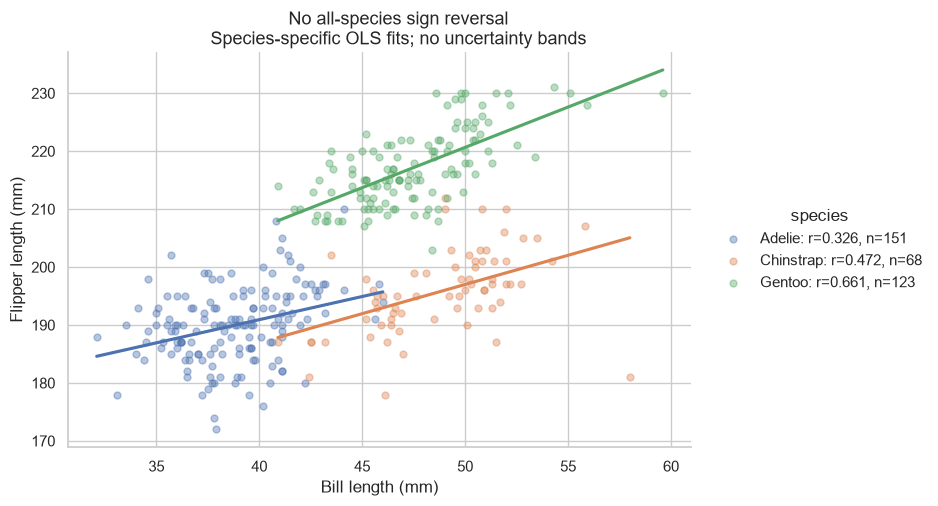

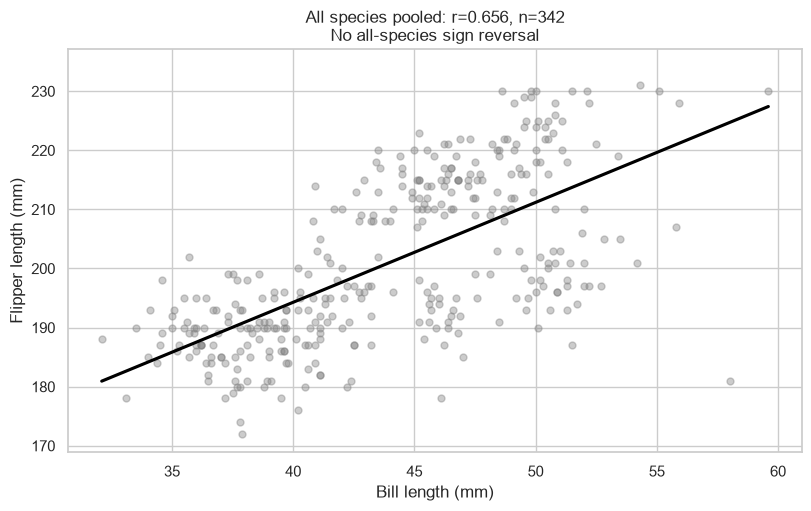

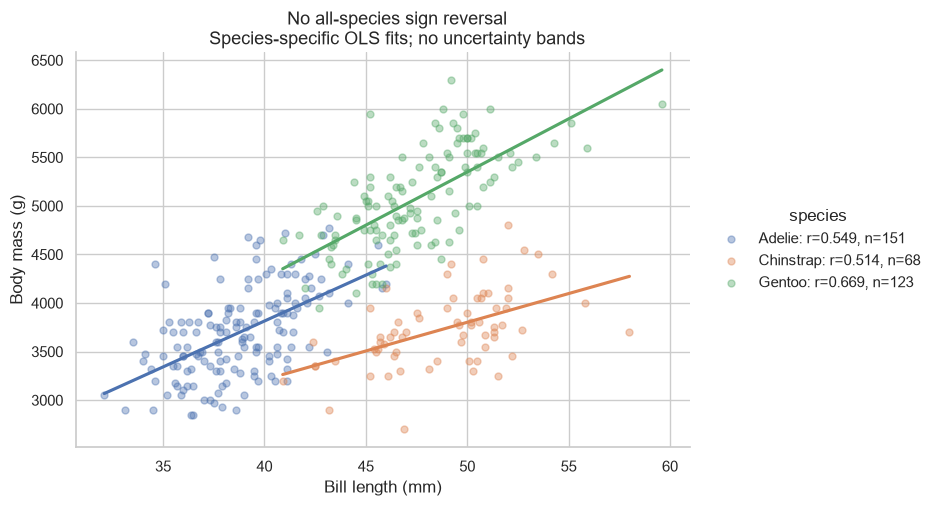

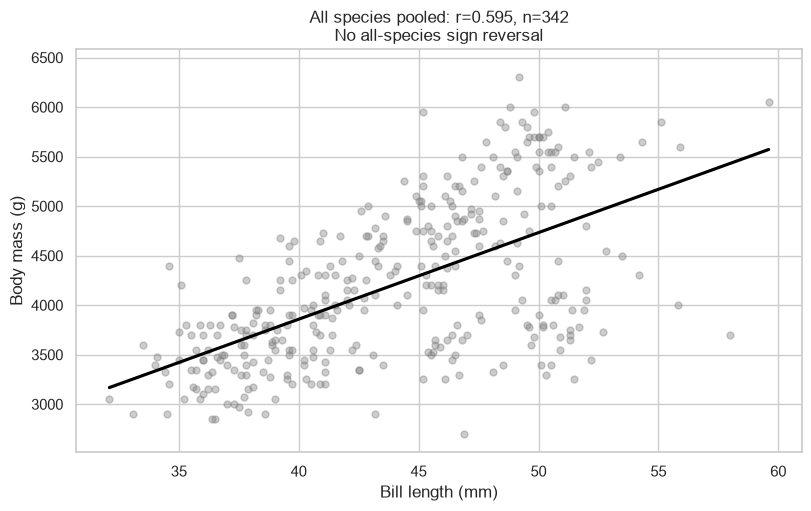

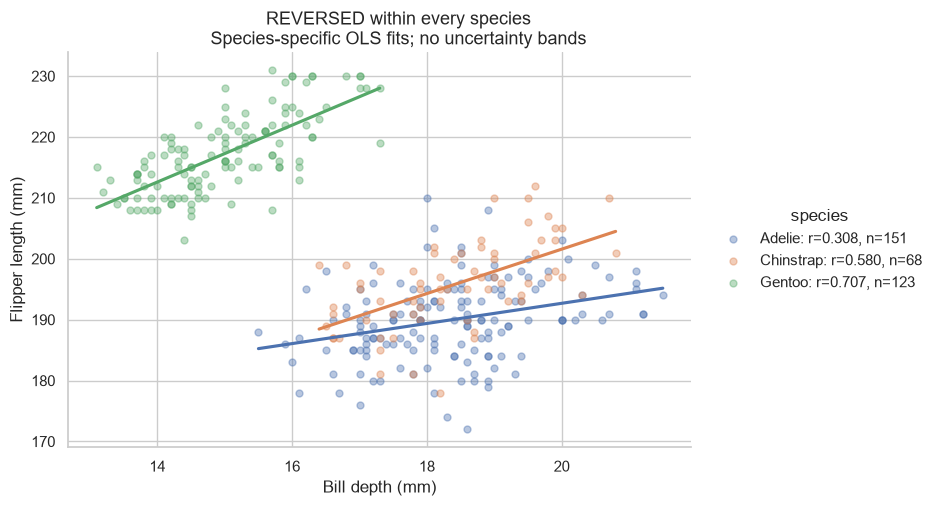

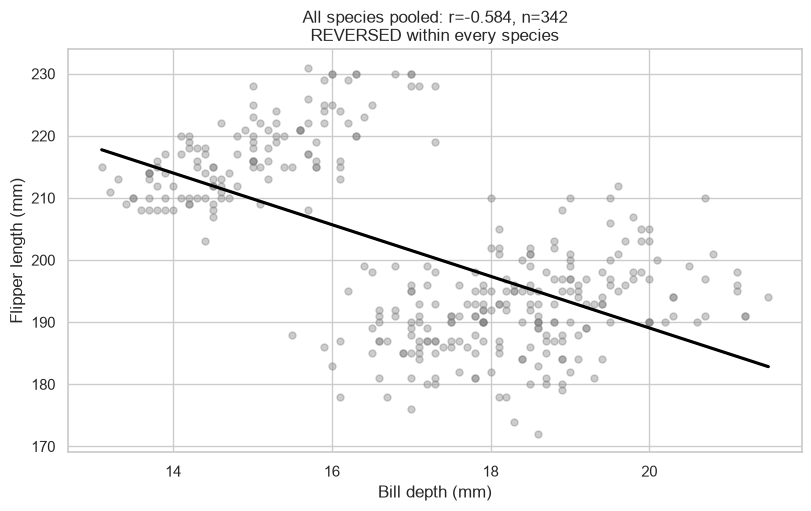

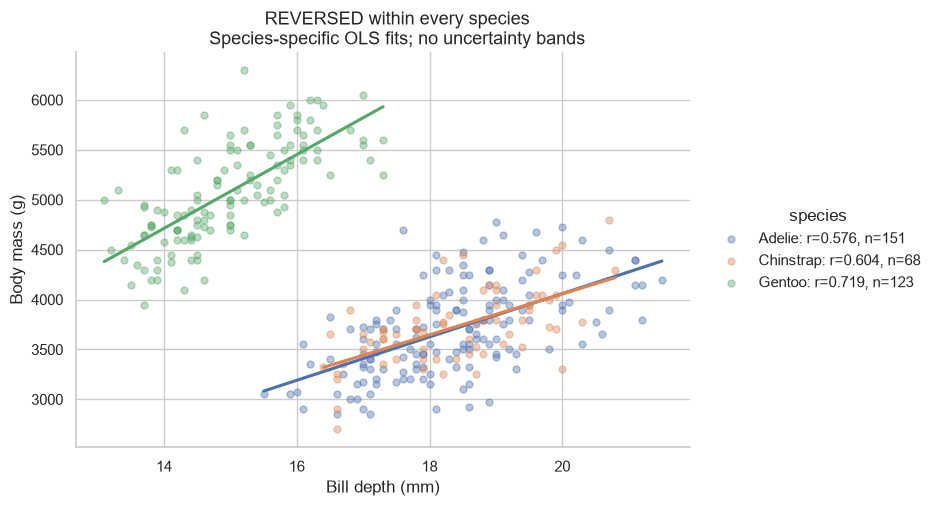

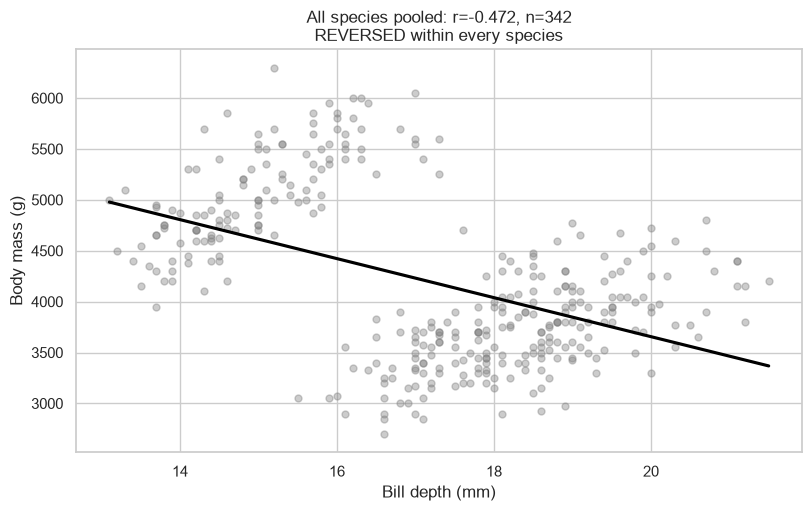

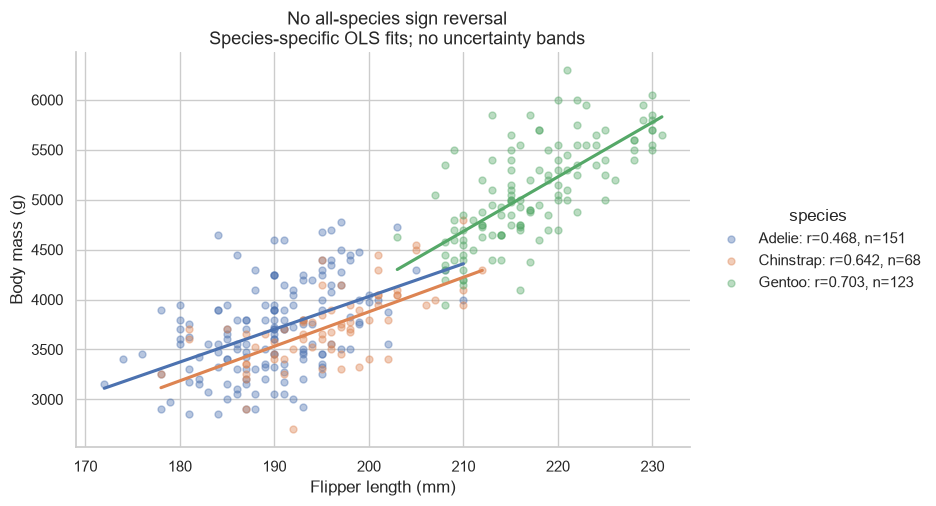

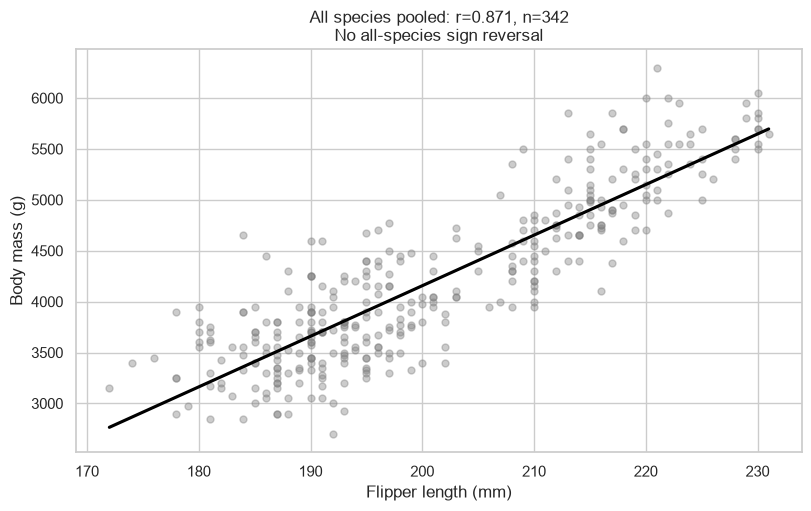

,x,y,pooled_r,Adelie_r,Chinstrap_r,Gentoo_r,reversal_all_species
0,bill_length_mm,bill_depth_mm,-0.235053,0.391492,0.653536,0.643384,True
1,bill_length_mm,flipper_length_mm,0.656181,0.325785,0.471607,0.661162,False
2,bill_length_mm,body_mass_g,0.595110,0.548866,0.513638,0.669166,False
3,bill_depth_mm,flipper_length_mm,-0.583851,0.307620,0.580143,0.706563,True
4,bill_depth_mm,body_mass_g,-0.471916,0.576138,0.604498,0.719085,True
5,flipper_length_mm,body_mass_g,0.871202,0.468202,0.641559,0.702667,False


PASS: six pairs, 24 source-verified correlations/slopes, 12 figures, exactly the three reversals found in Module 07.


In [18]:
# Optional investigation: all six pairs, not just selected reversals.
from itertools import combinations
import csv
import statistics
import math

hunt_axis_labels = {
    'bill_length_mm': 'Bill length (mm)', 'bill_depth_mm': 'Bill depth (mm)',
    'flipper_length_mm': 'Flipper length (mm)', 'body_mass_g': 'Body mass (g)',
}
hunt_rows = []
for hunt_x, hunt_y in combinations(MEASUREMENTS, 2):
    hunt_r_all = penguins[hunt_x].corr(penguins[hunt_y])
    hunt_row = {'x': hunt_x, 'y': hunt_y, 'pooled_n': len(penguins), 'pooled_r': hunt_r_all,
                'pooled_slope': np.polyfit(penguins[hunt_x], penguins[hunt_y], 1)[0]}
    hunt_group_rs = []
    hunt_legend_labels = []
    for hunt_species in SPECIES_ORDER:
        hunt_group = penguins.loc[penguins['species'] == hunt_species]
        hunt_r = hunt_group[hunt_x].corr(hunt_group[hunt_y])
        hunt_row[hunt_species + '_n'] = len(hunt_group)
        hunt_row[hunt_species + '_r'] = hunt_r
        hunt_row[hunt_species + '_slope'] = np.polyfit(hunt_group[hunt_x], hunt_group[hunt_y], 1)[0]
        hunt_group_rs.append(hunt_r)
        hunt_legend_labels.append(f'{hunt_species}: r={hunt_r:.3f}, n={len(hunt_group)}')
    hunt_reversed = all(np.isfinite(hunt_r) and np.sign(hunt_r) != 0 and np.sign(hunt_r_all) != 0
                        and np.sign(hunt_r) != np.sign(hunt_r_all) for hunt_r in hunt_group_rs)
    hunt_row['reversal_all_species'] = hunt_reversed
    hunt_rows.append(hunt_row)
    hunt_status = 'REVERSED within every species' if hunt_reversed else 'No all-species sign reversal'
    hunt_stem = f'paradox_hunt_{hunt_x}__{hunt_y}'

    # Figure-level Seaborn regression, fitting one line per species.
    hunt_grid = sns.lmplot(data=penguins, x=hunt_x, y=hunt_y, hue='species',
                           hue_order=SPECIES_ORDER, palette=palette, ci=None,
                           height=4.8, aspect=1.5, scatter_kws={'alpha': .4, 's': 25})
    hunt_grid.set_axis_labels(hunt_axis_labels[hunt_x], hunt_axis_labels[hunt_y])
    for hunt_text, hunt_label in zip(hunt_grid.legend.get_texts(), hunt_legend_labels):
        hunt_text.set_text(hunt_label)
    hunt_grid.legend.set_loc('center left')
    hunt_grid.legend.set_bbox_to_anchor((1.02, .5), transform=hunt_grid.ax.transAxes)
    hunt_grid.figure.suptitle(f'{hunt_status}\nSpecies-specific OLS fits; no uncertainty bands', y=1.05, fontsize=13)
    hunt_xlim, hunt_ylim = hunt_grid.ax.get_xlim(), hunt_grid.ax.get_ylim()
    hunt_grid.savefig(OUT / (hunt_stem + '_species.png'), dpi=120, bbox_inches='tight')
    plt.show()
    plt.close(hunt_grid.figure)

    # A separate pooled regplot uses exactly the same observations and limits.
    hunt_fig, hunt_ax = plt.subplots(figsize=(8, 5), layout='constrained')
    sns.regplot(data=penguins, x=hunt_x, y=hunt_y, ci=None, ax=hunt_ax,
                scatter_kws={'alpha': .4, 'color': 'gray', 's': 25}, line_kws={'color': 'black'})
    hunt_ax.set(title=f'All species pooled: r={hunt_r_all:.3f}, n={len(penguins)}\n{hunt_status}',
                xlabel=hunt_axis_labels[hunt_x], ylabel=hunt_axis_labels[hunt_y],
                xlim=hunt_xlim, ylim=hunt_ylim)
    hunt_fig.savefig(OUT / (hunt_stem + '_pooled.png'), dpi=120, bbox_inches='tight')
    plt.show()
    plt.close(hunt_fig)

paradox_hunt = pd.DataFrame(hunt_rows)
paradox_hunt.to_csv(OUT / 'paradox_hunt_summary.csv', index=False)
display(paradox_hunt[['x', 'y', 'pooled_r'] + [species + '_r' for species in SPECIES_ORDER] + ['reversal_all_species']].round(6))

# Independent CSV + statistics verification of all 24 correlations and slopes.
with open('penguins.csv', newline='', encoding='utf-8') as hunt_handle:
    hunt_raw = list(csv.DictReader(hunt_handle))
hunt_complete = [row for row in hunt_raw if all(row[column] != '' for column in MEASUREMENTS)]
assert len(hunt_complete) == 342
for hunt_row in paradox_hunt.to_dict('records'):
    for hunt_name, hunt_records in [('pooled', hunt_complete)] + [
        (species, [row for row in hunt_complete if row['species'] == species]) for species in SPECIES_ORDER]:
        hunt_first = [float(row[hunt_row['x']]) for row in hunt_records]
        hunt_second = [float(row[hunt_row['y']]) for row in hunt_records]
        assert hunt_row[hunt_name + '_n'] == len(hunt_records)
        assert math.isclose(hunt_row[hunt_name + '_r'], statistics.correlation(hunt_first, hunt_second))
        assert math.isclose(hunt_row[hunt_name + '_slope'], statistics.linear_regression(hunt_first, hunt_second).slope)
        assert np.sign(hunt_row[hunt_name + '_r']) == np.sign(hunt_row[hunt_name + '_slope'])
hunt_reversed_pairs = set(map(tuple, paradox_hunt.loc[paradox_hunt['reversal_all_species'], ['x', 'y']].to_numpy()))
assert len(paradox_hunt) == 6 and hunt_reversed_pairs == {
    ('bill_length_mm', 'bill_depth_mm'),
    ('bill_depth_mm', 'flipper_length_mm'),
    ('bill_depth_mm', 'body_mass_g'),
}
assert len(list(OUT.glob('paradox_hunt_*_species.png'))) == 6
assert len(list(OUT.glob('paradox_hunt_*_pooled.png'))) == 6
print('PASS: six pairs, 24 source-verified correlations/slopes, 12 figures, exactly the three reversals found in Module 07.')


**Optional investigation findings:** Three of the six pairs reverse from a negative pooled slope to positive slopes within **all three species**, matching Module 07's complete pair analysis:

- Bill length vs. bill depth: pooled r = **-0.235**.
- Bill depth vs. flipper length: pooled r = **-0.584**.
- Bill depth vs. body mass: pooled r = **-0.472**.

The other three pairs have positive pooled and within-species relationships. Gentoo penguins tend to have shallower bills but longer flippers and greater body mass than the other species; between-species offsets can dominate and reverse the upward trends within species. The full summary includes all six pairs and all group sizes (151 Adelie, 68 Chinstrap, 123 Gentoo), using the same 342 complete-measurement records throughout and retaining nine penguins with unknown sex. Each pooled/species figure pair shares limits; fitted lines are descriptive OLS fits without confidence or prediction bands. No reversal establishes a causal effect, and the exploratory scan is not a significance test.

### Verification of required work

These independent source-data calculations verify the plotted estimates and group sizes. The optional paradox hunt is completed and independently checked above.


In [19]:
# Independent CSV-based verification of required results and grouping choices.
import csv
import math
import statistics
from collections import Counter
from itertools import combinations

def read_records(filename):
    with open(filename, newline='', encoding='utf-8') as handle:
        return list(csv.DictReader(handle))

p_records = read_records('penguins.csv')
complete_records = [row for row in p_records if all(row[column] != '' for column in MEASUREMENTS)]
assert len(p_records) == 344 and len(complete_records) == len(penguins) == 342
assert Counter(row['species'] for row in complete_records) == {'Adelie': 151, 'Chinstrap': 68, 'Gentoo': 123}
assert sum(row['sex'] == '' for row in complete_records) == penguins['sex'].isna().sum() == 9

def corr_reference(records, first, second):
    pairs = [(float(row[first]), float(row[second])) for row in records if row[first] != '' and row[second] != '']
    return statistics.correlation([row[0] for row in pairs], [row[1] for row in pairs])

def close(actual, expected):
    assert math.isclose(float(actual), expected, rel_tol=1e-10, abs_tol=1e-12), (actual, expected)

close(r_all, corr_reference(complete_records, 'bill_length_mm', 'bill_depth_mm'))
print(f'Overall bill correlation: r={r_all:.6f}, n={len(complete_records)}')
assert r_all < 0
for species in SPECIES_ORDER:
    records = [row for row in complete_records if row['species'] == species]
    group = penguins.loc[penguins['species'] == species]
    ref = corr_reference(records, 'bill_length_mm', 'bill_depth_mm')
    assert ref > 0
    close(group['bill_length_mm'].corr(group['bill_depth_mm']), ref)
    values = [float(row['body_mass_g']) for row in records]
    assert mass_summary.loc[species, 'count'] == len(values)
    close(mass_summary.loc[species, 'mean'], statistics.mean(values))
    close(mass_summary.loc[species, 'std'], statistics.stdev(values))
    print(f'{species}: bill r={ref:.6f}, n={len(records)}')
close(penguins['flipper_length_mm'].corr(penguins['body_mass_g']), corr_reference(complete_records, 'flipper_length_mm', 'body_mass_g'))
for row in regression_summary.itertuples(index=False):
    records = [record for record in complete_records if record['species'] == row.species and record['sex'].title() == row.sex]
    first = [float(record['flipper_length_mm']) for record in records]
    second = [float(record['body_mass_g']) for record in records]
    assert row.n == len(records)
    close(row.pearson_r, statistics.correlation(first, second))
    close(row.slope_g_per_mm, statistics.linear_regression(first, second).slope)
assert regression_summary['n'].sum() == 333 and regression_summary['slope_g_per_mm'].gt(0).all()
pokemon_records = read_records('pokemon.csv')
independent_pairs = []
for first, second in combinations(stats, 2):
    reference = corr_reference(pokemon_records, first, second)
    close(pokemon_corr.loc[first, second], reference)
    independent_pairs.append(((first, second), reference))
independent_pairs.sort(key=lambda item: abs(item[1]), reverse=True)
assert len(pokemon_pairs) == 15
assert pokemon_pairs.index[0] == independent_pairs[0][0] == ('Defense', 'Sp. Def')
for legendary, group in pokemon_scatter.groupby('Legendary'):
    records = [row for row in pokemon_records if row['Legendary'].lower() == str(legendary).lower()]
    assert len(records) == legendary_summary.loc[legendary, 'n']
    close(legendary_summary.loc[legendary, 'median_attack'], statistics.median(float(row['Attack']) for row in records))
    close(legendary_summary.loc[legendary, 'median_special_attack'], statistics.median(float(row['Sp. Atk']) for row in records))
assert quadratic_mse < linear_mse / 100000
close(linear_mse, statistics.mean((float(y) - float(prediction)) ** 2 for y, prediction in
      zip(dataset_ii['y'], np.polyval(linear_coefficients, dataset_ii['x']))))
expected_files = ['penguin_paradox.png', 'penguin_pairplot.png', 'anscombe_ii_quadratic.png',
                  'pokemon_attack_special_attack.png', 'pokemon_correlation_heatmap.png',
                  'body_mass_ci_vs_sd.png', 'flipper_mass_lmplot.png']
assert all((OUT / filename).stat().st_size > 1000 for filename in expected_files)
print('PASS: independent aggregate/within-species correlations, sample sizes, sample SDs, sex-specific slopes, strongest Pokemon pair and saved figures.')
print('Species mixture explains the direction reversal; neither pooled nor grouped correlations establish causation.')


Overall bill correlation: r=-0.235053, n=342
Adelie: bill r=0.391492, n=151
Chinstrap: bill r=0.653536, n=68
Gentoo: bill r=0.643384, n=123
PASS: independent aggregate/within-species correlations, sample sizes, sample SDs, sex-specific slopes, strongest Pokemon pair and saved figures.
Species mixture explains the direction reversal; neither pooled nor grouped correlations establish causation.


## 📦 Check Your Output Files
Run this last. Everything you saved should be inside `04-OutputFiles`. Upload that folder along with this notebook.

In [20]:
for path in sorted(OUT.rglob('*')):
    print(path)

04-OutputFiles\anscombe_ii_quadratic.png
04-OutputFiles\body_mass_ci_vs_sd.png
04-OutputFiles\flipper_mass_lmplot.png
04-OutputFiles\paradox_hunt_bill_depth_mm__body_mass_g_pooled.png
04-OutputFiles\paradox_hunt_bill_depth_mm__body_mass_g_species.png
04-OutputFiles\paradox_hunt_bill_depth_mm__flipper_length_mm_pooled.png
04-OutputFiles\paradox_hunt_bill_depth_mm__flipper_length_mm_species.png
04-OutputFiles\paradox_hunt_bill_length_mm__bill_depth_mm_pooled.png
04-OutputFiles\paradox_hunt_bill_length_mm__bill_depth_mm_species.png
04-OutputFiles\paradox_hunt_bill_length_mm__body_mass_g_pooled.png
04-OutputFiles\paradox_hunt_bill_length_mm__body_mass_g_species.png
04-OutputFiles\paradox_hunt_bill_length_mm__flipper_length_mm_pooled.png
04-OutputFiles\paradox_hunt_bill_length_mm__flipper_length_mm_species.png
04-OutputFiles\paradox_hunt_flipper_length_mm__body_mass_g_pooled.png
04-OutputFiles\paradox_hunt_flipper_length_mm__body_mass_g_species.png
04-OutputFiles\paradox_hunt_summary.csv
04

---
✅ Next up → [Choosing and Telling](05-Choosing_and_Telling.ipynb): how to pick the right chart, keep it honest, and make it say one clear thing.